In [1]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

class SketchDataset(Dataset):
            
    def __init__(self, images_path, labels_path, indices_path, split):

        self.images = np.load(images_path, mmap_mode="r")
        self.labels = np.load(labels_path, mmap_mode="r")
        splits = np.load(indices_path)
        self.indices = splits[f"{split}_idx"]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        actual_index = self.indices[index]
        image = self.images[actual_index].reshape(28, 28)
        label = self.labels[actual_index]

        image = torch.tensor(
            image.copy(),
            dtype = torch.float32
        ) / 255.0
        
        image = image.unsqueeze(0)
        label = torch.tensor(label, dtype = torch.long)
        
        return image, label
        

In [2]:
DATA_DIR = "../data/processed"

train_dataset = SketchDataset(
    f"{DATA_DIR}/images.npy",
    f"{DATA_DIR}/labels.npy",
    f"{DATA_DIR}/split_indices.npz",
    "train"
)

val_dataset = SketchDataset(
    f"{DATA_DIR}/images.npy",
    f"{DATA_DIR}/labels.npy",
    f"{DATA_DIR}/split_indices.npz",
    "val"
)

test_dataset = SketchDataset(
    f"{DATA_DIR}/images.npy",
    f"{DATA_DIR}/labels.npy",
    f"{DATA_DIR}/split_indices.npz",
    "test"
)
   

In [3]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [4]:

import torch.nn as nn

class SketchCNN(nn.Module):
    def __init__(self, num_classes=50):
        super().__init__()
        self.features = nn.Sequential(
            # First conv block
            nn.Conv2d( in_channels=1, out_channels=32, kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # Second conv block
            nn.Conv2d( in_channels=32, out_channels=64, kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            #3rd conv block
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
            
        

In [5]:
import json
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path("../data/processed")

with open(DATA_DIR / "class_to_idx.json", "r") as f:
    class_to_idx = json.load(f)

num_classes = len(class_to_idx)

idx_to_class = {
    index: category
    for category, index in class_to_idx.items()
}

model = SketchCNN(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(f"Device: {device}")
print(f"Number of classes: {num_classes}")
print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer}")

Device: cuda
Number of classes: 15
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        
        #clear gradients from prev batch
        optimizer.zero_grad()
        
        # forward pass
        outputs = model(images)
        
        #calc loss
        loss = criterion(outputs, labels)
        
        #backward pass
        loss.backward()
        
        # update weights
        optimizer.step()
        
        # track loss
        running_loss += loss.item() * images.size(0)
        
        #track accuracy
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy

In [7]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            #forward
            outputs = model(images)

            #loss
            loss = criterion(outputs, labels)

            #track loss
            running_loss += loss.item() * images.size(0)
            #trach accuracy
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy



In [8]:
import time
import copy

NUM_EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_state = None
best_epoch = 0

for epoch in range(NUM_EPOCHS):
    start_time = time.time()
    #training
    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)
    #validate
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)
    # store metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    #save best
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        
    epoch_time = time.time() - start_time

    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy:.4f}")
    print(f"Best Val Accuracy: {best_val_accuracy:.4f}")
    print(f"Best Epoch: {best_epoch}")
    print(f"Time: {epoch_time:.2f} seconds")
    print("-" * 50)

Epoch [1/10]
Train Loss: 0.2589 | Train Accuracy: 0.9216
Val Loss:   0.1823 | Val Accuracy:   0.9436
Best Val Accuracy: 0.9436
Best Epoch: 1
Time: 338.14 seconds
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.1827 | Train Accuracy: 0.9440
Val Loss:   0.1704 | Val Accuracy:   0.9467
Best Val Accuracy: 0.9467
Best Epoch: 2
Time: 334.35 seconds
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.1615 | Train Accuracy: 0.9502
Val Loss:   0.1588 | Val Accuracy:   0.9508
Best Val Accuracy: 0.9508
Best Epoch: 3
Time: 333.71 seconds
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.1461 | Train Accuracy: 0.9543
Val Loss:   0.1587 | Val Accuracy:   0.9512
Best Val Accuracy: 0.9512
Best Epoch: 4
Time: 335.00 seconds
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.1342 | Train Accuracy: 0.9574
Val Loss:   0.1568 | Val Accuracy:   0.9520
Best Val Accuracy: 0.9520
Best Epoch: 5
Time: 3

In [9]:
from pathlib import Path
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint = {
    "model_state_dict" : model.state_dict(),
    "class_to_idx" : class_to_idx,
    "num_classes" : num_classes,
    "best_epoch" : best_epoch,
    "best_val_accuracy": best_val_accuracy
}

torch.save(checkpoint, MODEL_DIR / "sketch_cnn_15.pth")

print("50-class model saved successfully!")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")

50-class model saved successfully!
Best epoch: 8
Best validation accuracy: 0.9523


In [10]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.1825
Test Accuracy: 0.9511
Test Accuracy: 95.11%


In [11]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

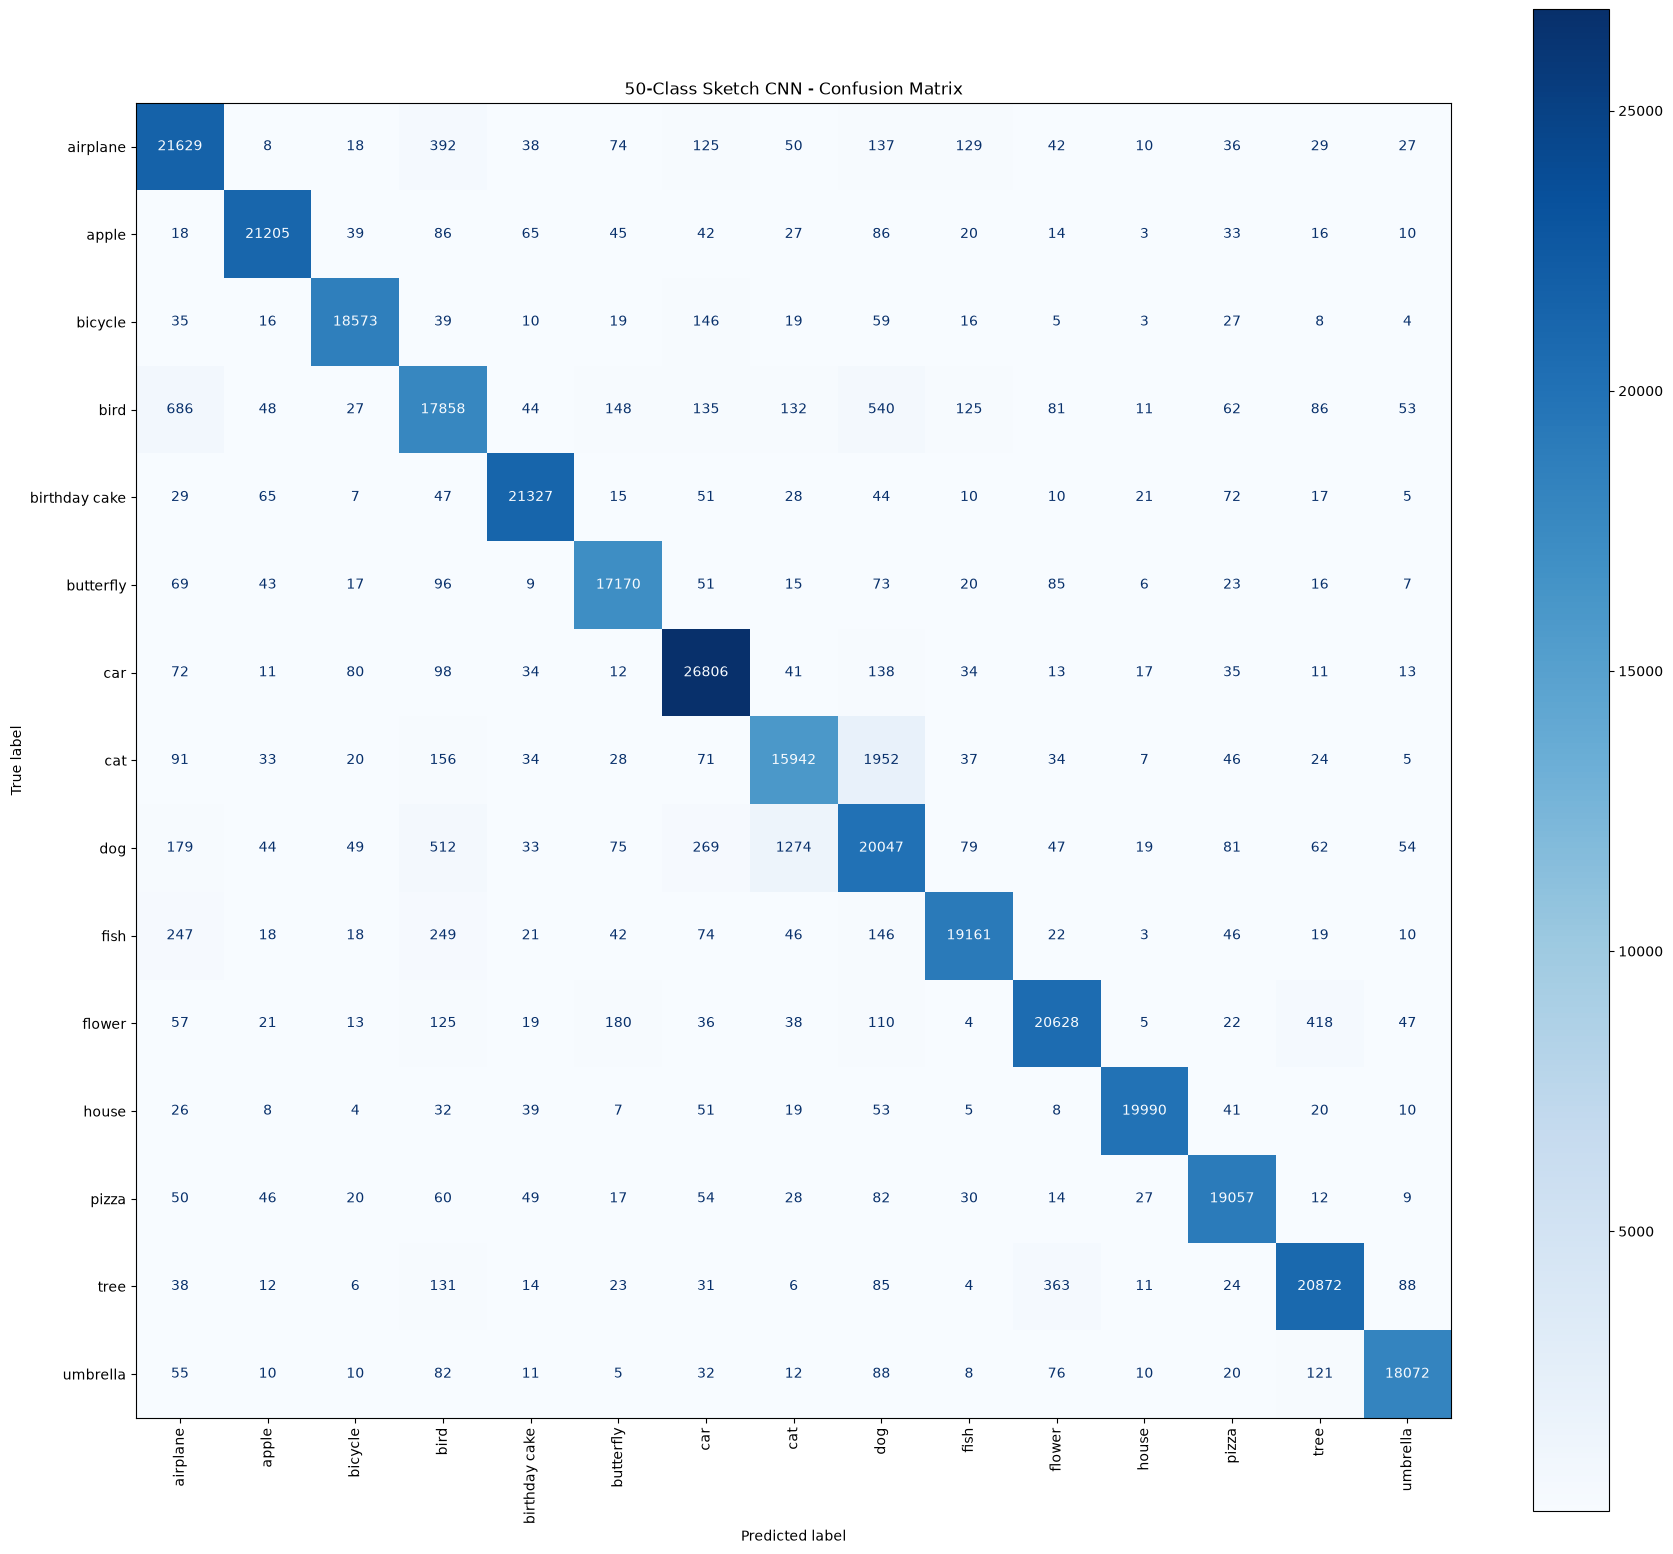

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    idx_to_class[i]
    for i in range(num_classes)
]

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(18, 16))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=90
)

plt.title("50-Class Sketch CNN - Confusion Matrix")
plt.tight_layout()
plt.show()